In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [3]:
data = pd.read_csv("/Users/macbookair/Desktop/Customer-Churn-Prediction/data/Telco-Customer-Churn.csv")

In [4]:
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [11]:
data.shape

(7043, 21)

In [13]:
data.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
data.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [9]:
data.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [10]:
data.duplicated().sum()

np.int64(0)

In [14]:
data['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

# Task 2A — Investigate TotalCharges

In [15]:
data['TotalCharges'].unique()[:20]


array(['29.85', '1889.5', '108.15', '1840.75', '151.65', '820.5',
       '1949.4', '301.9', '3046.05', '3487.95', '587.45', '326.8',
       '5681.1', '5036.3', '2686.05', '7895.15', '1022.95', '7382.25',
       '528.35', '1862.9'], dtype=object)

In [16]:
print("Blank values: ",
      (data["TotalCharges"].str.strip() == "").sum())

Blank values:  11


In [17]:
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")

In [18]:
data["TotalCharges"].isnull().sum()

np.int64(11)

With errors='coerce': Pandas forces the conversion, turns the bad/invalid entries into NaN  

and same missing values apear after conversion

# Task 2B — Visualize the churn distribution

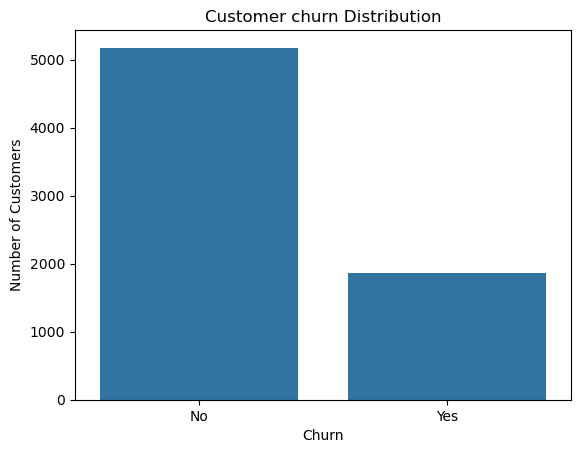

In [19]:
import seaborn as sns

sns.countplot(data=data, x = "Churn")

plt.title("Customer churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

In [22]:
print(
    (data["Churn"].value_counts(normalize=True)*100).round(2)
)

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


1. Is the dataset balanced or imbalanced?
=> the dataset is imbalanced
2. If a model predicts No for every customer, what accuracy will it achieve?
=> 73.46
3. Why could that accuracy be misleading for a churn-prediction business?
=> the model has 0% recall for churned customers. It fails to identify every customer who leaves and if I mark all the customer to "NO" we will lose a huge amount of customer without knowing

# Task 3: Discover why customers churn

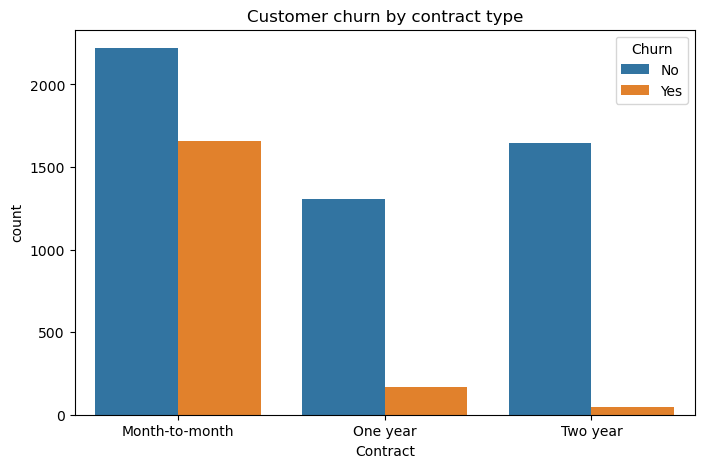

In [23]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=data,
    x = "Contract",
    hue = "Churn"
)

plt.title("Customer churn by contract type")
plt.show()

In [26]:
contract_churn = pd.crosstab(
    data["Contract"],
    data["Churn"],
    normalize="index"
) * 100

contract_churn

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


1. Which contract type has the highest churn rate? Why might customers with month-to-month contracts be more likely to leave?

=> month-to-month contract type has the highest churn rate 
=> ig it is about the duration or habit

Analyze churn by customer tenure


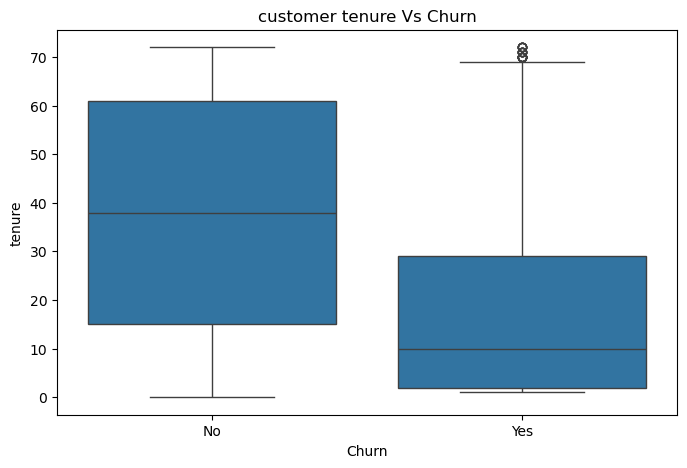

In [27]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=data,
    x = "Churn",
    y = "tenure"
)

plt.title("customer tenure Vs Churn")
plt.show()

In [28]:
print(
    data.groupby("Churn")["tenure"].agg(
        ["mean", "median"]
    ).round(2)
)

        mean  median
Churn               
No     37.57    38.0
Yes    17.98    10.0


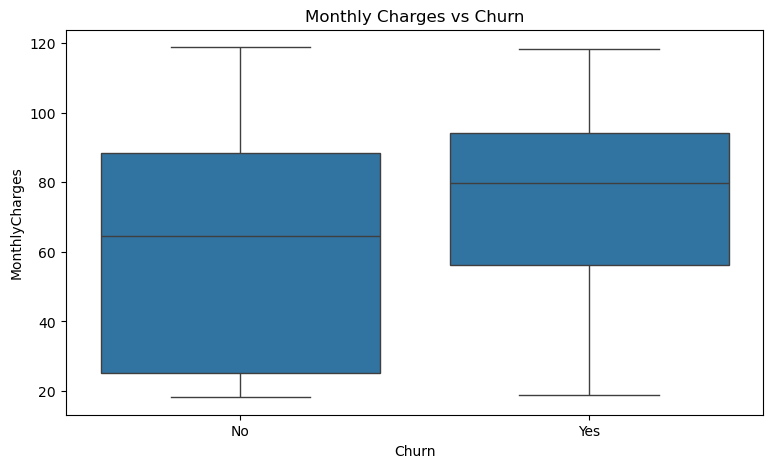

In [30]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=data,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Churn")
plt.show()

In [31]:
print(
    data.groupby("Churn")["MonthlyCharges"].agg(
        ["mean", "median"]
    ).round(2)
)

        mean  median
Churn               
No     61.27   64.43
Yes    74.44   79.65


1. Your interpretation of the three findings.

=> one or two year contarct is good for customer retaining. more tenure less customer churn . more monthly charge more churn

In [34]:
# Churn rate by contract type
print(
    data.groupby("Contract", observed=True)["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
      .round(2)
)

# Churn rate by tenure group
data["TenureGroup"] = pd.cut(
    data["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12", "13-24", "25-48", "49-72"]
)

print(
    data.groupby("TenureGroup", observed=False)["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
      .round(2)
)

Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64
TenureGroup
0-12     47.44
13-24    28.71
25-48    20.39
49-72     9.51
Name: Churn, dtype: float64
